In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
url='https://raw.githubusercontent.com/rashakil-ds/Machine-Learning-with-Python/refs/heads/master/weight-height.csv'
df=pd.read_csv(url)

In [2]:
df.head()

,Gender,Height,Weight
0,Male,73.847017,241.893563
1,Male,68.781904,162.310473
2,Male,74.110105,212.740856
3,Male,71.730978,220.042470
4,Male,69.881796,206.349801


In [3]:
df.isnull().sum()

Gender    0
Height    0
Weight    0
dtype: int64

In [4]:
df.shape

(8555, 3)

<Axes: ylabel='Weight'>

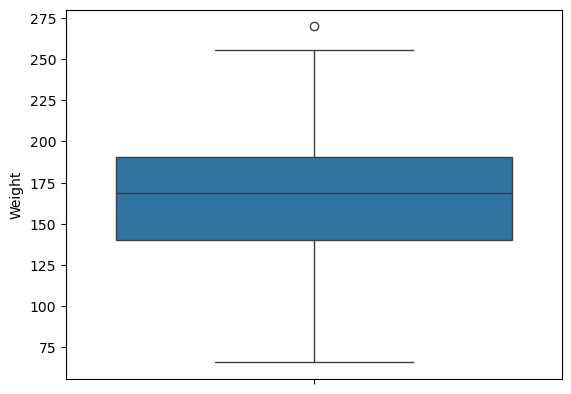

In [5]:
sns.boxplot(data=df['Weight'])

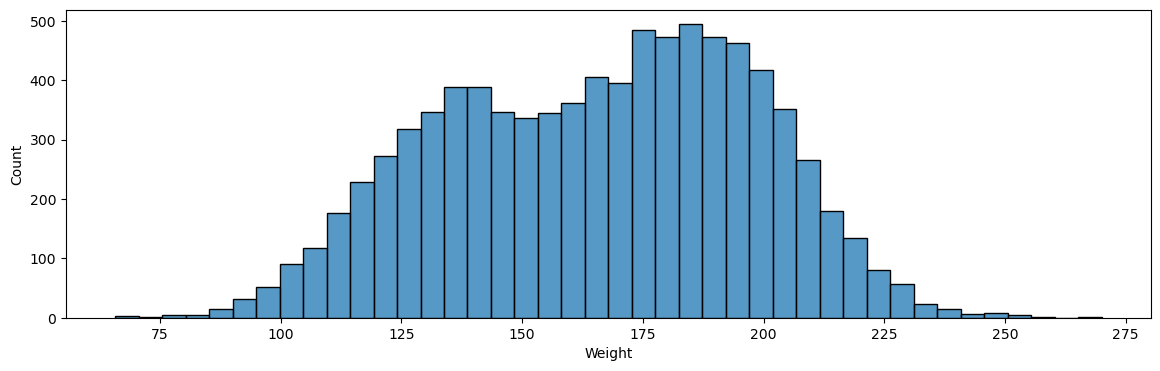

In [6]:
plt.figure(figsize=(14,4))
sns.histplot(data=df['Weight'],kde=False)
plt.show()

In [7]:
mean=df['Weight'].mean()
std=df['Weight'].std()
positive_std_25=mean+(std*2.5)
negtive_std_25=mean-(std*2.5)

In [8]:
positive_std_25

245.74254086971553

In [9]:
negtive_std_25

85.52292978363808

In [10]:
df[df['Weight']>positive_std_25]

,Gender,Height,Weight
994,Male,78.095867,255.690835
1506,Male,75.698618,249.565628
1610,Male,76.617546,255.863326
1750,Male,74.604668,249.946283
1896,Male,76.472880,246.232321
2014,Male,78.998742,269.989698
2070,Male,77.465569,252.556689
2971,Male,75.156879,250.317151
3228,Male,76.268668,247.386741
3285,Male,78.528210,253.889004


In [11]:
df[df['Weight']<negtive_std_25]

,Gender,Height,Weight
151,Male,65.350411,65.780000
160,Male,64.333648,68.640000
5026,Female,56.547975,84.872124
5214,Female,56.785434,83.993077
5360,Female,55.668202,68.982530
5740,Female,56.108902,80.531259
6624,Female,54.616858,71.393749
6982,Female,56.764456,79.174376
7294,Female,54.873728,78.606670
7324,Female,56.810317,84.170695


In [12]:
df['Weight'].shape[0]

8555

In [13]:
outlier=(df[(df['Weight']<negtive_std_25) | (df['Weight']>positive_std_25)].shape[0])

In [14]:
(outlier*100)/df['Weight'].shape[0]

0.31560490940970193

In [15]:
100-((outlier*100)/df['Weight'].shape[0])

99.6843950905903

In [16]:
outlier_cols=df[(df['Weight']<negtive_std_25) | (df['Weight']>positive_std_25)]

In [17]:
outlier_cols.shape

(27, 3)

In [18]:
outlier_removed=pd.concat([df,outlier_cols]).drop_duplicates(keep=False)

In [19]:
outlier_removed.shape

(8528, 3)

In [20]:
df[(df['Weight']>negtive_std_25) & (df['Weight']<positive_std_25)].shape

(8528, 3)

<Axes: ylabel='Weight'>

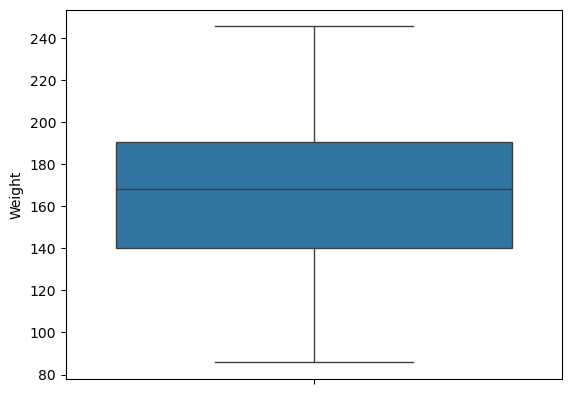

In [21]:
sns.boxplot(data=outlier_removed['Weight'])

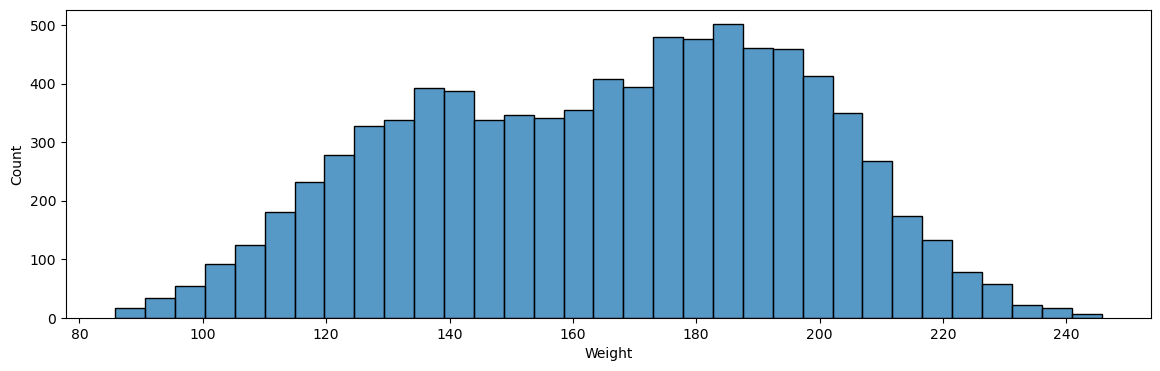

In [22]:
plt.figure(figsize=(14,4))
sns.histplot(data=outlier_removed['Weight'],kde=False)
plt.show()

In [23]:
gender_encoded=pd.get_dummies(outlier_removed['Gender'],drop_first=True,dtype=float)
outlier_removed.drop(['Gender'],axis=1,inplace=True)

In [58]:
df_2=pd.concat([outlier_removed,gender_encoded],axis=1)

In [79]:
x=df_2.iloc[:,1:]
y=df_2.drop(x,axis=1)

In [85]:
y

,Height
0,73.847017
1,68.781904
2,74.110105
3,71.730978
4,69.881796
...,...
8550,60.483946
8551,63.423372
8552,65.584057
8553,67.429971


In [87]:
from sklearn.model_selection import train_test_split

In [89]:
X_train,X_test,y_train,y_test=train_test_split(x,y,test_size=.30,random_state=42)

In [91]:
from sklearn.linear_model import LinearRegression

In [93]:
lr=LinearRegression()

In [95]:
lr.fit(X_train,y_train)

LinearRegression()

In [97]:
from sklearn.metrics import r2_score

In [99]:
y_pred=lr.predict(X_test)

In [103]:
score=r2_score(y_test,y_pred)
print(f'Accuracy of Linear Regression is: {score*100:.2f}%')

Accuracy of Linear Regression is: 85.35%


In [105]:
from sklearn.metrics import mean_squared_error

In [107]:
from sklearn.neighbors import KNeighborsRegressor

In [109]:
X_train.shape

(5969, 2)

In [139]:
knn=KNeighborsRegressor(n_neighbors=300, metric='manhattan')

In [141]:
knn.fit(X_train,y_train)

KNeighborsRegressor(metric='manhattan', n_neighbors=300)

In [143]:
y_pred_knn=knn.predict(X_test)

In [145]:
score=r2_score(y_test,y_pred)
print(f'Accuracy of Linear Regression is: {score*100:.2f}% \n')

score_knn=r2_score(y_test,y_pred_knn)
print(f'Accuracy of KNN Regression is: {score_knn*100:.2f}% \n')

mse=mean_squared_error(y_test,y_pred)
print(f'Mean Squared Error of Lienar Regression is: {mse} \n')

mse_knn=mean_squared_error(y_test,y_pred_knn)
print(f'Mean Squared Error of KNN Regression is: {mse_knn}')


Accuracy of Linear Regression is: 85.35% 

Accuracy of KNN Regression is: 84.56% 

Mean Squared Error of Lienar Regression is: 2.0824049723793876 

Mean Squared Error of KNN Regression is: 2.195239785664507


In [ ]:
from sklearn.neighbors import KNeighborsClassifier
knn2=KNeighborsClassifier()